,subject_id,sex,screen_time_index,est_leisure_screen_hours,sleep_quality_index,avg_sleep_hours,midsleep_weekend_hours,social_jetlag_hours,bdi_total,depressed
0,1,Boy,3.333,4.64,2.25,8.36,4.58,1.92,6,0
1,2,Girl,3.333,4.07,2.50,7.31,5.42,2.25,7,0
2,3,Boy,3.333,4.07,2.00,8.75,5.50,2.62,27,1
3,4,Boy,4.333,6.07,1.50,8.17,6.62,3.96,22,1
4,5,Boy,1.667,0.50,2.50,8.88,4.12,1.79,3,0


<class 'pandas.DataFrame'>
RangeIndex: 4810 entries, 0 to 4809
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   subject_id                4810 non-null   int64  
 1   sex                       4810 non-null   str    
 2   screen_time_index         4810 non-null   float64
 3   est_leisure_screen_hours  4810 non-null   float64
 4   sleep_quality_index       4810 non-null   float64
 5   avg_sleep_hours           4810 non-null   float64
 6   midsleep_weekend_hours    4810 non-null   float64
 7   social_jetlag_hours       4810 non-null   float64
 8   bdi_total                 4810 non-null   int64  
 9   depressed                 4810 non-null   int64  
dtypes: float64(6), int64(3), str(1)
memory usage: 375.9 KB


None

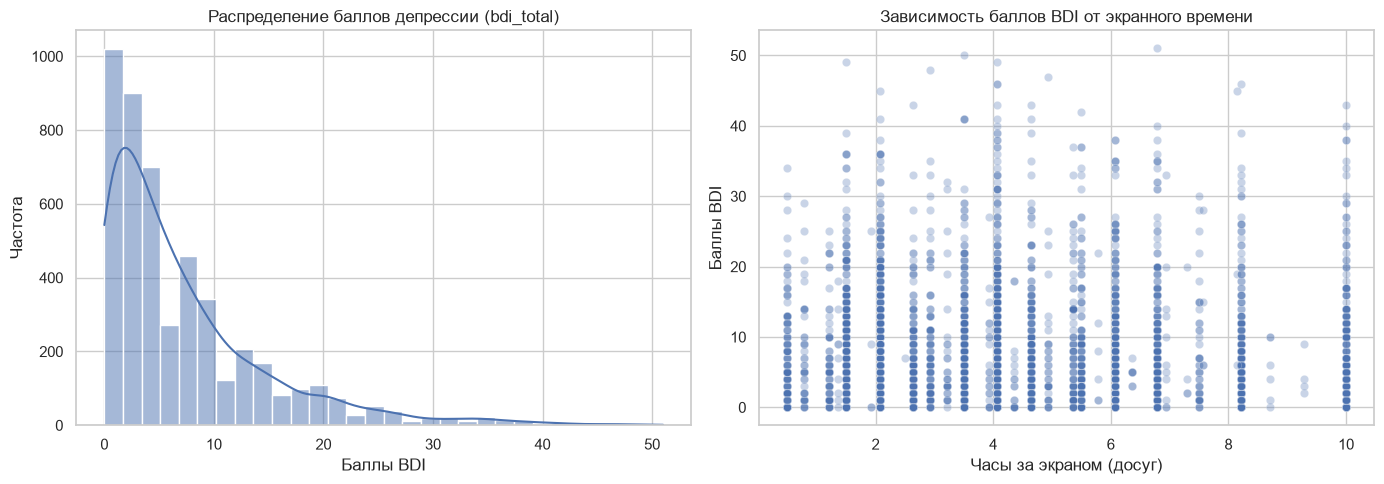

Количество пропусков в каждом столбце:
 sex                         0
screen_time_index           0
est_leisure_screen_hours    0
sleep_quality_index         0
avg_sleep_hours             0
midsleep_weekend_hours      0
social_jetlag_hours         0
bdi_total                   0
dtype: int64


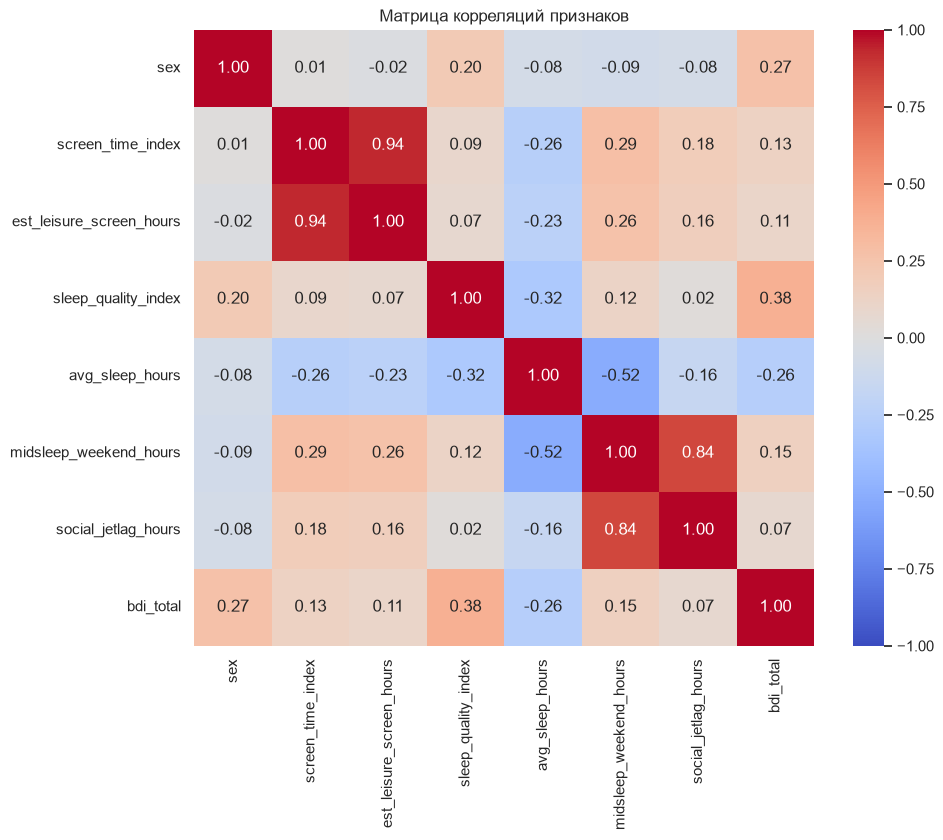


Коэффициенты VIF (Variance Inflation Factor):


,Признак,VIF
0,sex,1.077786
1,screen_time_index,8.168056
2,est_leisure_screen_hours,8.020856
3,sleep_quality_index,1.155520
4,avg_sleep_hours,2.247521
5,midsleep_weekend_hours,6.960390
6,social_jetlag_hours,5.093596


Результаты на исходных признаках:


,CV RMSE (Mean),Test RMSE,Test R²,Test MAPE
Linear Regression,6.805930,6.990597,0.219908,2.333150e+15
Ridge (L2),6.805915,6.990545,0.219920,2.333447e+15
Lasso (L1),6.809868,6.990404,0.219951,2.404129e+15


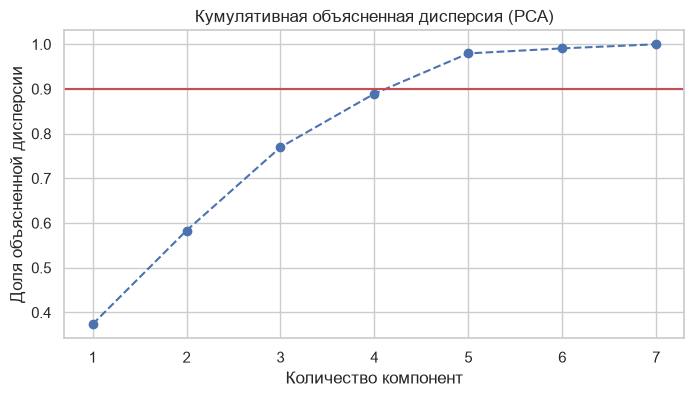

Размерность до PCA: 7, после PCA: 5
Результаты на главных компонентах (PCA):


,CV RMSE (Mean),Test RMSE,Test R²,Test MAPE
Linear Regression,6.810500,6.980783,0.222097,2.348656e+15
Ridge (L2),6.810496,6.980796,0.222094,2.348890e+15
Lasso (L1),6.812837,6.977083,0.222922,2.388872e+15


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.decomposition import PCA
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Отключаем предупреждения для чистоты вывода
import warnings
warnings.filterwarnings('ignore')


# Загрузка датасета
df = pd.read_csv("screen_time_mental_health.csv")

# Вывод первых строк и информации о типах данных
display(df.head())
display(df.info())

# Настройка стиля графиков
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Распределение целевой переменной (bdi_total)
sns.histplot(df['bdi_total'], bins=30, kde=True, ax=axes[0])
axes[0].set_title('Распределение баллов депрессии (bdi_total)')
axes[0].set_xlabel('Баллы BDI')
axes[0].set_ylabel('Частота')

# 2. Зависимость между часами за экраном и баллами депрессии
sns.scatterplot(x='est_leisure_screen_hours', y='bdi_total', data=df, alpha=0.3, ax=axes[1])
axes[1].set_title('Зависимость баллов BDI от экранного времени')
axes[1].set_xlabel('Часы за экраном (досуг)')
axes[1].set_ylabel('Баллы BDI')

plt.tight_layout()
plt.show()

# 1. Удаление нерелевантных столбцов:
# subject_id - идентификатор, не несет предсказательной силы
# depressed - бинарный флаг депрессии (создаст утечку данных, т.к. напрямую зависит от bdi_total)
df_clean = df.drop(columns=['subject_id', 'depressed'])

# 2. Кодирование категориальной переменной 'sex'
df_clean['sex'] = df_clean['sex'].map({'Boy': 0, 'Girl': 1})

# Проверка на наличие пропущенных значений
print("Количество пропусков в каждом столбце:\n", df_clean.isna().sum())

# Матрица корреляций
plt.figure(figsize=(10, 8))
sns.heatmap(df_clean.corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Матрица корреляций признаков')
plt.show()

# Расчет коэффициента VIF для проверки на мультиколлинеарность
def calculate_vif(X):
    # Стандартизация необходима для корректного расчета VIF
    scaler = StandardScaler()
    X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
    
    vif_data = pd.DataFrame()
    vif_data["Признак"] = X.columns
    vif_data["VIF"] = [variance_inflation_factor(X_scaled.values, i) for i in range(X_scaled.shape[1])]
    return vif_data

# Формируем матрицу признаков (без целевой переменной)
X_features = df_clean.drop('bdi_total', axis=1)
print("\nКоэффициенты VIF (Variance Inflation Factor):")
display(calculate_vif(X_features))

# Выделение признаков и целевой переменной
X = df_clean.drop('bdi_total', axis=1)
y = df_clean['bdi_total']

# Разделение на тренировочную и тестовую выборки (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Стандартизация данных (критически важно для Лассо, Гребневой регрессии и PCA)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    'Linear Regression': LinearRegression(),
    'Ridge (L2)': Ridge(alpha=1.0),
    'Lasso (L1)': Lasso(alpha=0.1)
}

def evaluate_models(models, X_tr, y_tr, X_te, y_te):
    results = {}
    for name, model in models.items():
        # Кросс-валидация
        cv_scores = cross_val_score(model, X_tr, y_tr, cv=5, scoring='neg_root_mean_squared_error')
        
        # Обучение модели
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_te)
        
        # Расчет метрик
        rmse = np.sqrt(mean_squared_error(y_te, y_pred))
        r2 = r2_score(y_te, y_pred)
        mape = mean_absolute_percentage_error(y_te, y_pred)
        
        results[name] = {
            'CV RMSE (Mean)': -cv_scores.mean(),
            'Test RMSE': rmse,
            'Test R²': r2,
            'Test MAPE': mape
        }
    return pd.DataFrame(results).T

results_original = evaluate_models(models, X_train_scaled, y_train, X_test_scaled, y_test)
print("Результаты на исходных признаках:")
display(results_original)

# Обучение PCA
pca = PCA(random_state=42)
pca.fit(X_train_scaled)

# Визуализация кумулятивной объясненной дисперсии
explained_variance = pca.explained_variance_ratio_
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(explained_variance) + 1), np.cumsum(explained_variance), marker='o', linestyle='--')
plt.axhline(y=0.90, color='r', linestyle='-')
plt.title('Кумулятивная объясненная дисперсия (PCA)')
plt.xlabel('Количество компонент')
plt.ylabel('Доля объясненной дисперсии')
plt.grid(True)
plt.show()

# Применение PCA (оставляем компоненты, объясняющие около 90% дисперсии — обычно это 5 компонент из 7)
pca_final = PCA(n_components=5, random_state=42)
X_train_pca = pca_final.fit_transform(X_train_scaled)
X_test_pca = pca_final.transform(X_test_scaled)

print(f"Размерность до PCA: {X_train_scaled.shape[1]}, после PCA: {X_train_pca.shape[1]}")


results_pca = evaluate_models(models, X_train_pca, y_train, X_test_pca, y_test)
print("Результаты на главных компонентах (PCA):")
display(results_pca)